# Task 1: Dataset Loading & Initial Exploration
Loading my dataset and perform initial exploration using pandas.

Deliverables:
* Code showing data loading
* Dataset shape (rows, columns)
* First 5 rows display
* Data types of all columns
* Basic statistical summary
* Initial missing value check


In [ ]:
#Data Loading
import pandas as pd

df = '../data/raw/ObesityDataSet_raw_and_data_sinthetic.csv'
df = pd.read_csv(df)

#First 5 rows display
df.head(5)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [25]:
#Shape
df.shape

(2111, 17)

In [26]:
#Summary statistics of numerical variables (mean, std, min, max):
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [27]:
#Data types
df.dtypes

Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object

In [28]:
#Initial Missing Value Check.
df.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

# Task 2: Data Quality Assessment

Systematically identify and document data quality issues, such as missing values, duplicate
values, and outliers.

Deliverables:
* Missing values table with percentages
* Missing values heatmap
* Duplicate count and examples (if any)
* Boxplots for all numerical features
* Initial observations about data quality

In [29]:
#Missing values table with percentages
missing_val_table = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': df.isnull().mean() * 100
})

missing_val_table

,Missing Count,Missing %
Gender,0,0.0
Age,0,0.0
Height,0,0.0
Weight,0,0.0
family_history_with_overweight,0,0.0
FAVC,0,0.0
FCVC,0,0.0
NCP,0,0.0
CAEC,0,0.0
SMOKE,0,0.0


In [30]:
# #Missing Values Heatmap
# import seaborn as sns
# import matplotlib.pyplot as plt

# plt.figure(figsize=(12, 6))
# sns.heatmap(df.isnull())
# plt.title('Missing Values Heatmap')
# plt.tight_layout()
# plt.show()

## ==> There's no missing values, therefore, this Heatmap is pointless.

In [31]:
#Checking for number of duplicates original
print(df.duplicated().sum())

#Data shape for references
print(df.shape)

#Actual duplicated records:
print(df[df.duplicated(keep=False)].shape)

#View duplicated records:
df[df.duplicated(keep=False)]

# Drop duplicates, keeping the first occurrence
df = df.drop_duplicates(keep='first')

#After drop shapes for references
print(df.shape)

24
(2111, 17)
(33, 17)
(2087, 17)


In [32]:
## Boxplot all numerical values:
#print(df.dtypes)
numerical_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
df.boxplot(column=numerical_cols, rot=45, figsize=(20, 10))

<Axes: >

In [33]:
#Summary statistics of numerical variables

print(df[numerical_cols].describe())

               Age       Height       Weight         FCVC          NCP  \
count  2087.000000  2087.000000  2087.000000  2087.000000  2087.000000   
mean     24.353090     1.702674    86.858730     2.421466     2.701179   
std       6.368801     0.093186    26.190847     0.534737     0.764614   
min      14.000000     1.450000    39.000000     1.000000     1.000000   
25%      19.915937     1.630178    66.000000     2.000000     2.697467   
50%      22.847618     1.701584    83.101100     2.396265     3.000000   
75%      26.000000     1.769491   108.015907     3.000000     3.000000   
max      61.000000     1.980000   173.000000     3.000000     4.000000   

              CH2O          FAF          TUE  
count  2087.000000  2087.000000  2087.000000  
mean      2.004749     1.012812     0.663035  
std       0.608284     0.853475     0.608153  
min       1.000000     0.000000     0.000000  
25%       1.590922     0.124505     0.000000  
50%       2.000000     1.000000     0.630866  
75% 

In [34]:
#IQR cal
q1 = df[numerical_cols].quantile(0.25)
q3 = df[numerical_cols].quantile(0.75)

iqr = q3 - q1

print("IQR: \n")
print(iqr)

#Bound Cal
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

#Print Bound as table
bound = pd.DataFrame({
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound
})
print(f"\n{bound} \n")

#Outlier Detection
outlier_mask = (df[numerical_cols] < lower_bound) | (df[numerical_cols] > upper_bound)
print(outlier_mask.sum())


IQR: 

Age        6.084063
Height     0.139313
Weight    42.015907
FCVC       1.000000
NCP        0.302533
CH2O       0.875271
FAF        1.553597
TUE        1.000000
dtype: float64

        Lower Bound  Upper Bound
Age       10.789844    35.126094
Height     1.421209     1.978461
Weight     2.976140   171.039767
FCVC       0.500000     4.500000
NCP        2.243667     3.453799
CH2O       0.278015     3.779099
FAF       -2.205890     4.008497
TUE       -1.500000     2.500000 

Age       167
Height      1
Weight      1
FCVC        0
NCP       577
CH2O        0
FAF         0
TUE         0
dtype: int64


In [35]:
# Inspect what the extreme values look like
print(f"{df['NCP'].value_counts().sort_index()} \n")
print(df['Age'].value_counts().sort_index())

## => The NCP and Age original ranges are reasonable eventhough IQR flagged them as outlier, I will leaves them as it
## (pretty sure it won't come up again later...).
## => Refer to univariate analysis for more info.

NCP
1.000000    179
1.000283      1
1.000414      1
1.000610      1
1.001383      1
           ... 
3.995957      1
3.998618      1
3.998766      1
3.999591      1
4.000000     69
Name: count, Length: 635, dtype: int64 

Age
14.000000    1
15.000000    1
16.000000    8
16.093234    1
16.129279    1
            ..
55.022494    1
55.137881    1
55.246250    1
56.000000    1
61.000000    1
Name: count, Length: 1402, dtype: int64


In [36]:
# Just 1 row, safe to drop
df['Height'] = df['Height'].clip(lower=lower_bound['Height'], upper=upper_bound['Height'])
df['Weight'] = df['Weight'].clip(lower=lower_bound['Weight'], upper=upper_bound['Weight'])

df.shape

(2087, 17)

In [37]:
#Boxplot after handling outlier for references.
df.boxplot(column=numerical_cols, rot=45, figsize=(20, 10))

<Axes: >

In [38]:
#dtypes after cleaning
df.dtypes

Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object

# Task 3: Target Variable Preparation
## 1.2 For Categorical Target Variables:
* If your target is already categorical, verify class distribution. If a severe imbalance
(>80% in one class) exists, document this challenge and note how it will affect
modelling.

Deliverables:
* Target variable name and data type
* Problem type determination (regression/classification)
* Target distribution visualisation
* Summary statistics
* Initial observations about the target

In [39]:
## df target name and datatypes
target = ["NObeyesdad"]

#target datatype
print(df[target].dtypes)
print("\n")

#Problem type: classification

NObeyesdad    object
dtype: object




In [40]:
#Target distribution
print(df[target].value_counts())
print("\n")

NObeyesdad         
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64




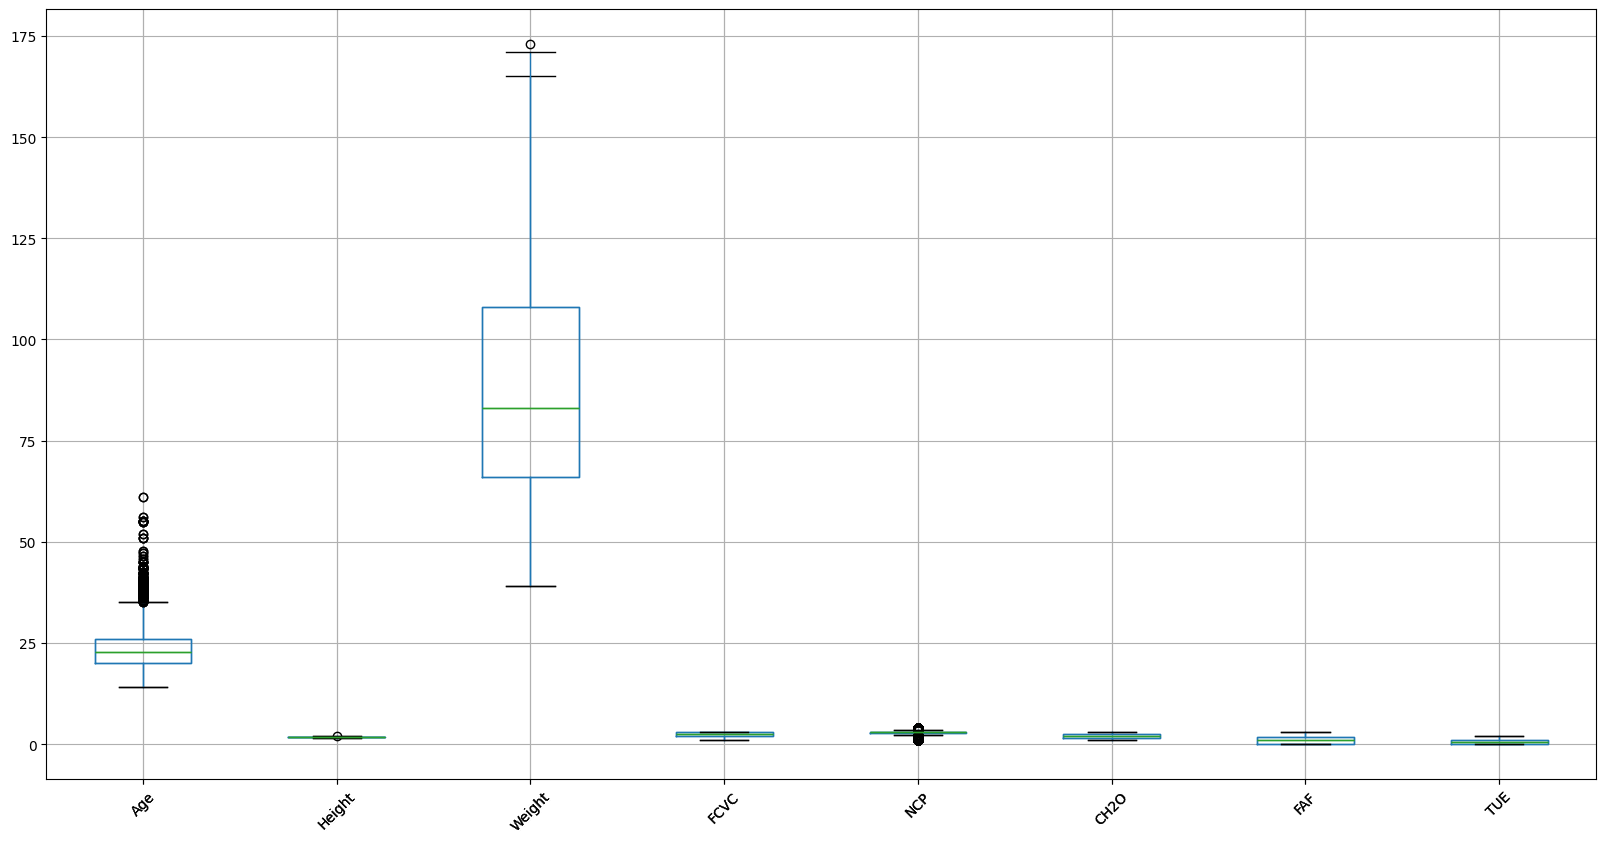

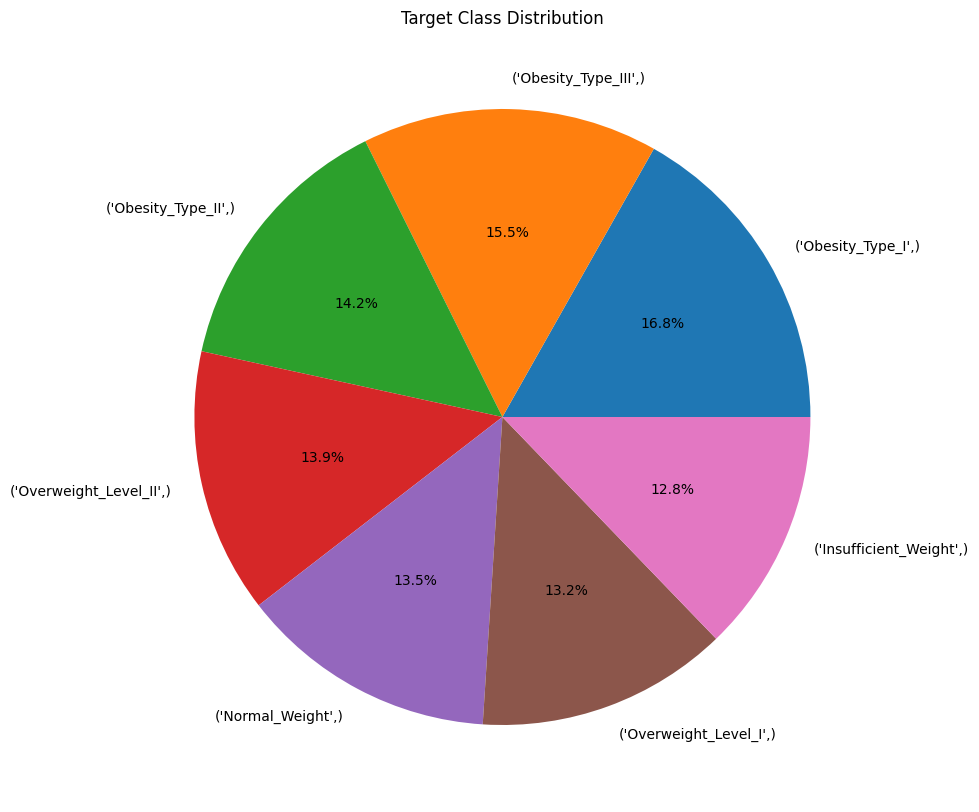

In [41]:
#Distribution visualization
import matplotlib.pyplot as plt


plt.figure(figsize=(20, 10))
plt.pie(
    df[target].value_counts(),
    labels=df[target].value_counts().index,
    autopct='%1.1f%%' #Show percentages
)
plt.title('Target Class Distribution')
plt.show()

In [42]:
#Summary statistic
df[target].describe()

,NObeyesdad
count,2087
unique,7
top,Obesity_Type_I
freq,351


# Task 4: Univariate Analysis
Analyse each predictor variable individually.

Deliverables:
* List of all predictors
* Distribution plots for numerical predictors (at least 6)
* Summary statistics table for all predictors
* Observations about distributions (normal, skewed, etc.)

In [43]:
#Listing all predictors
predictors = df.columns.drop(target)
print(predictors)

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE',
       'CALC', 'MTRANS'],
      dtype='object')


In [44]:
#Summerize statistic for all predictors
df[predictors].describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702673,86.857790,2.421466,2.701179,2.004749,1.012812,0.663035
std,6.368801,0.093184,26.187791,0.534737,0.764614,0.608284,0.853475,0.608153
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000
max,61.000000,1.978461,171.039767,3.000000,4.000000,3.000000,3.000000,2.000000


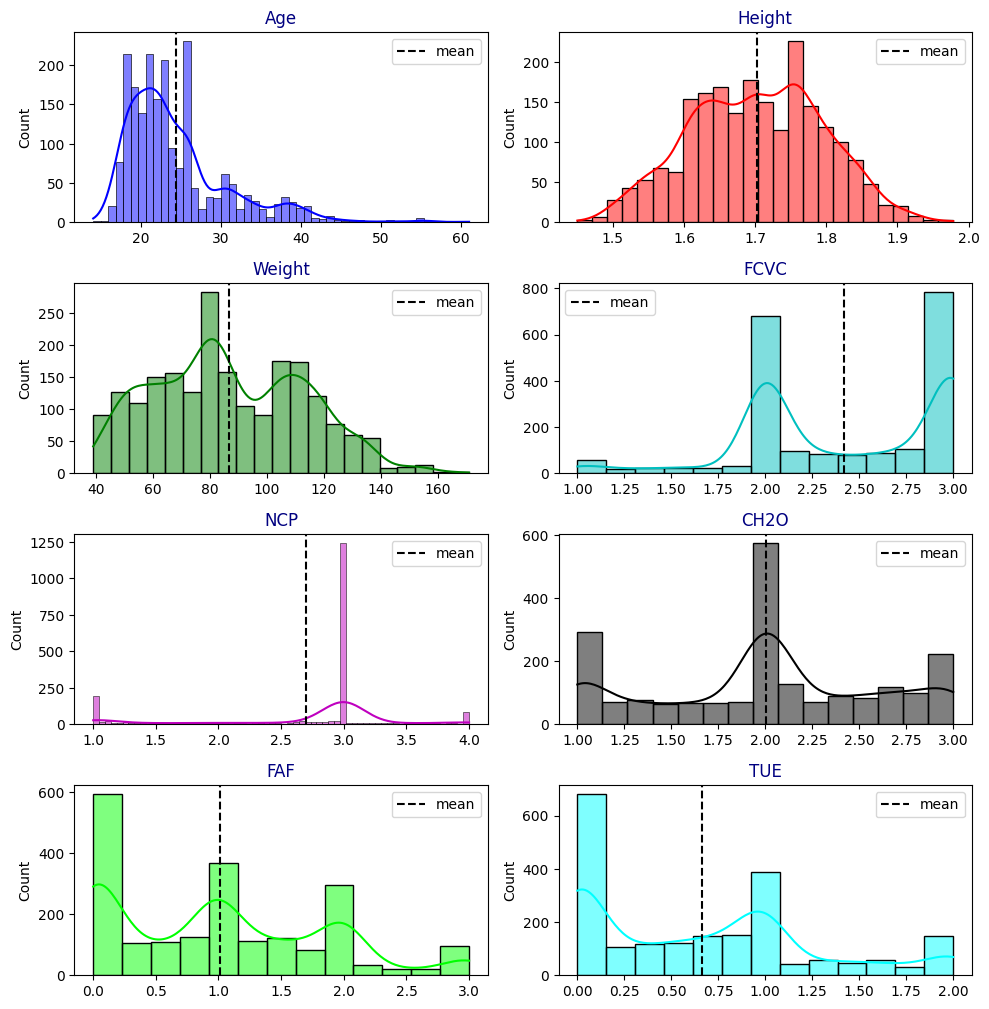

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

#Distribution plots for all numerical predictors
"""
Cited from the provided example within studio 1, section 5.2 Univariate Analysis
 (https://www.kaggle.com/code/vinayakshanawad/random-forest-with-bootstrap-sampling-for-beginner)
"""


#Numerical Cols is defined above


#Visualization
cs = ["b", "r", "g", "c", "m", "k", "lime", "cyan",
      "orange", "purple", "brown", "pink", "gray", "olive", "teal", "navy"]

fig = plt.figure(figsize=(10, 20))

for j, (i, k) in enumerate(zip(numerical_cols, cs)):
    plt.subplot(8, 2, j+1)
    sns.histplot(df[i], color=k, kde=True).set_facecolor("w")
    plt.axvline(df[i].mean(), linestyle="dashed", label="mean", color="k")
    plt.legend(loc="best")
    plt.title(i, color="navy")
    plt.xlabel("")

plt.tight_layout()
plt.show()

In [46]:
#Numerical distribution plots Description
"""
Ages:
- Most data bunched to the left, peak at around 20 - 25,
- The mean sits at around 25, far left from the middle of the chart.
- 1 peak at around bigger than 20.
=> Heavily right-skewed, unimodal.
=> The range bigger than 40 is considered as outlier (refer to boxplot above, I didn't drop).
=> Log transform should be considered.
=> The data is bias toward younger age from around 20 - 40, which could affect the model performance.


Height:
- Evenly spreaded within all range.
- The mean sits at the middle.
- Multiple peak continously next to each other (1.6 - 1.8) soo i consider it as 1 peak.
==> Unimoda, normal(symetric) data.


Weight:
- evenly spread from 40 - 140, peaked at around 80, sit on the left.
- The 140 - 160 could potentially outlier (IQR didn't flag as above).
- The mean sit a little on the left.
- 2 peak.
=> Bimodal, a little right skewed data.

FCVC:
- The vast majority is round values (1, 2, 3) but decimal values exists.
- Most values are 2 and 3.
- 2 peaks at 2 and 3.
=> Bimodal, skewness can't be decided due to the behavior, distribution of data.


NCP:
- The distribution behave same as FCVC (values concerntrate at rounded values at 1, 3, 4).
- Most of the MOST values concerntrated at 3 with barely any non-rounded values and number 2.
- 1 peak at 3.
=> Unimodal, skewness can't be decided.


===> NCP and FCVC are continuous float values but behave like int values
    and COULD BE CONSIDERED AS CATEGORICAL VALUES,
    by applying groundtruth dataset to convert continuous
    values into meaningful categories or just round it down into int values.


CH2O:
- evenly spread data with most data concerntrated in the middle at 2.
- some data concerntrated on 1 and 3, data are mostly evenly spreaded in betwee.
- 1 peak at sit closely in the middle at 2.
- The mean line sit closely in the middle at 2.
==> Beautiful synmetric, unimodal, evenly spreaded data.

FAF:
- Most value concerntrated in 0 > 1 > 2 > 3.
- 3 peaks at 0, 1, 2.
- The means sit on the left at nearly 1.
==> Right-skewed, multimodal data.

TUE:
- Most value concerntrated in 0 > 1 > 2.
- 2 peaks at 0, 1.
- The means sit on the left at around 0.74.
==> Right-skewed, multimodal data.


===>>>>> The patterns exist within this data is that mostly (if not all) numerical values is right skewed,
          mostly concerntrated on the left.
          Given the distribution, I conclude this data might be biased toward the age between 20 and 40
          because most data distribution is on the left.
"""

"\nAges:\n- Most data bunched to the left, peak at around 20 - 25,\n- The mean sits at around 25, far left from the middle of the chart.\n- 1 peak at around bigger than 20.\n=> Heavily right-skewed, unimodal.\n=> The range bigger than 40 is considered as outlier (refer to boxplot above, I didn't drop).\n=> Log transform should be considered.\n=> The data is bias toward younger age from around 20 - 40, which could affect the model performance.\n\n\nHeight:\n- Evenly spreaded within all range.\n- The mean sits at the middle.\n- Multiple peak continously next to each other (1.6 - 1.8) soo i consider it as 1 peak.\n==> Unimoda, normal(symetric) data.\n\n\nWeight:\n- evenly spread from 40 - 140, peaked at around 80, sit on the left.\n- The 140 - 160 could potentially outlier (IQR didn't flag as above).\n- The mean sit a little on the left.\n- 2 peak.\n=> Bimodal, a little right skewed data.\n\nFCVC:\n- The vast majority is round values (1, 2, 3) but decimal values exists.\n- Most values are

In [47]:
#Catagorical Distribution analysis:
Catagorical_features_cols = df.columns.drop(numerical_cols)
Catagorical_features_cols = Catagorical_features_cols.drop(target)
print(Catagorical_features_cols)

Index(['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE',
       'SCC', 'CALC', 'MTRANS'],
      dtype='object')


In [48]:
  # # Visualization
  # cs = ["b", "r", "g", "c", "m", "k", "lime", "cyan",
  #       "orange", "purple", "brown", "pink", "gray", "olive", "teal", "navy"]

  # fig = plt.figure(figsize=(10, 20))

  # for j, (i, c) in enumerate(zip(Catagorical_features_cols, cs)):
  #     plt.subplot(8, 2, j + 1)
  #     plt.pie(
  #         df[i].value_counts(),
  #         labels=df[i].value_counts().index,
  #         autopct='%1.1f%%',             # Show percentages
  #     )
  #     plt.legend(loc="best")
  #     plt.title(i, color="navy")
  #     plt.xlabel("")

  # plt.tight_layout()
  # plt.show()

# Task 5: Multivariate Analysis
Analyse relationships between variables.

Deliverables:
* Correlation heatmap
* Top 3 features correlated with the target (with coefficients)
* Identification of multicollinearity (high correlations between predictors)
* Pairplot of key features
* Observations about relationships and patterns

In [49]:
#Ordinal Encoding to Cata features data
YES_NO_MAP = {'yes': 1, 'no': 0}
Gender_MAP = {'Male': 1, 'Female': 0}
#map according to frequency intensity
CAEC_CALC_MAP = {'no': 0, 'Sometimes': 1, "Frequently": 2, "Always": 3}
#map according to intensity of travel activity (OneHotEn would be more suitable here) .
MTRANS_MAP = {'Walking': 0, "Bike": 1, "Motorbike": 2, "Automobile": 3, "Public_Transportation": 4}

In [50]:
#Mapping
df["Gender"] = df["Gender"].map(Gender_MAP)
df["family_history_with_overweight"] = df["family_history_with_overweight"].map(YES_NO_MAP)
df["FAVC"] = df["FAVC"].map(YES_NO_MAP)
df["CAEC"] = df["CAEC"].map(CAEC_CALC_MAP)
df["SMOKE"] = df["SMOKE"].map(YES_NO_MAP)
df["SCC"] = df["SCC"].map(YES_NO_MAP)
df["CALC"] = df["CALC"].map(CAEC_CALC_MAP)
df["MTRANS"] = df["MTRANS"].map(MTRANS_MAP)

In [51]:
#Target label Map
target_label_map = {
    'Insufficient_Weight': 0,
    'Normal_Weight': 1,
    'Overweight_Level_I': 2,
    'Overweight_Level_II': 3,
    'Obesity_Type_I': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}

df[target[0]] = df[target[0]].map(target_label_map)

In [52]:
#Correlation matrix
correlation_matrix = df.corr()

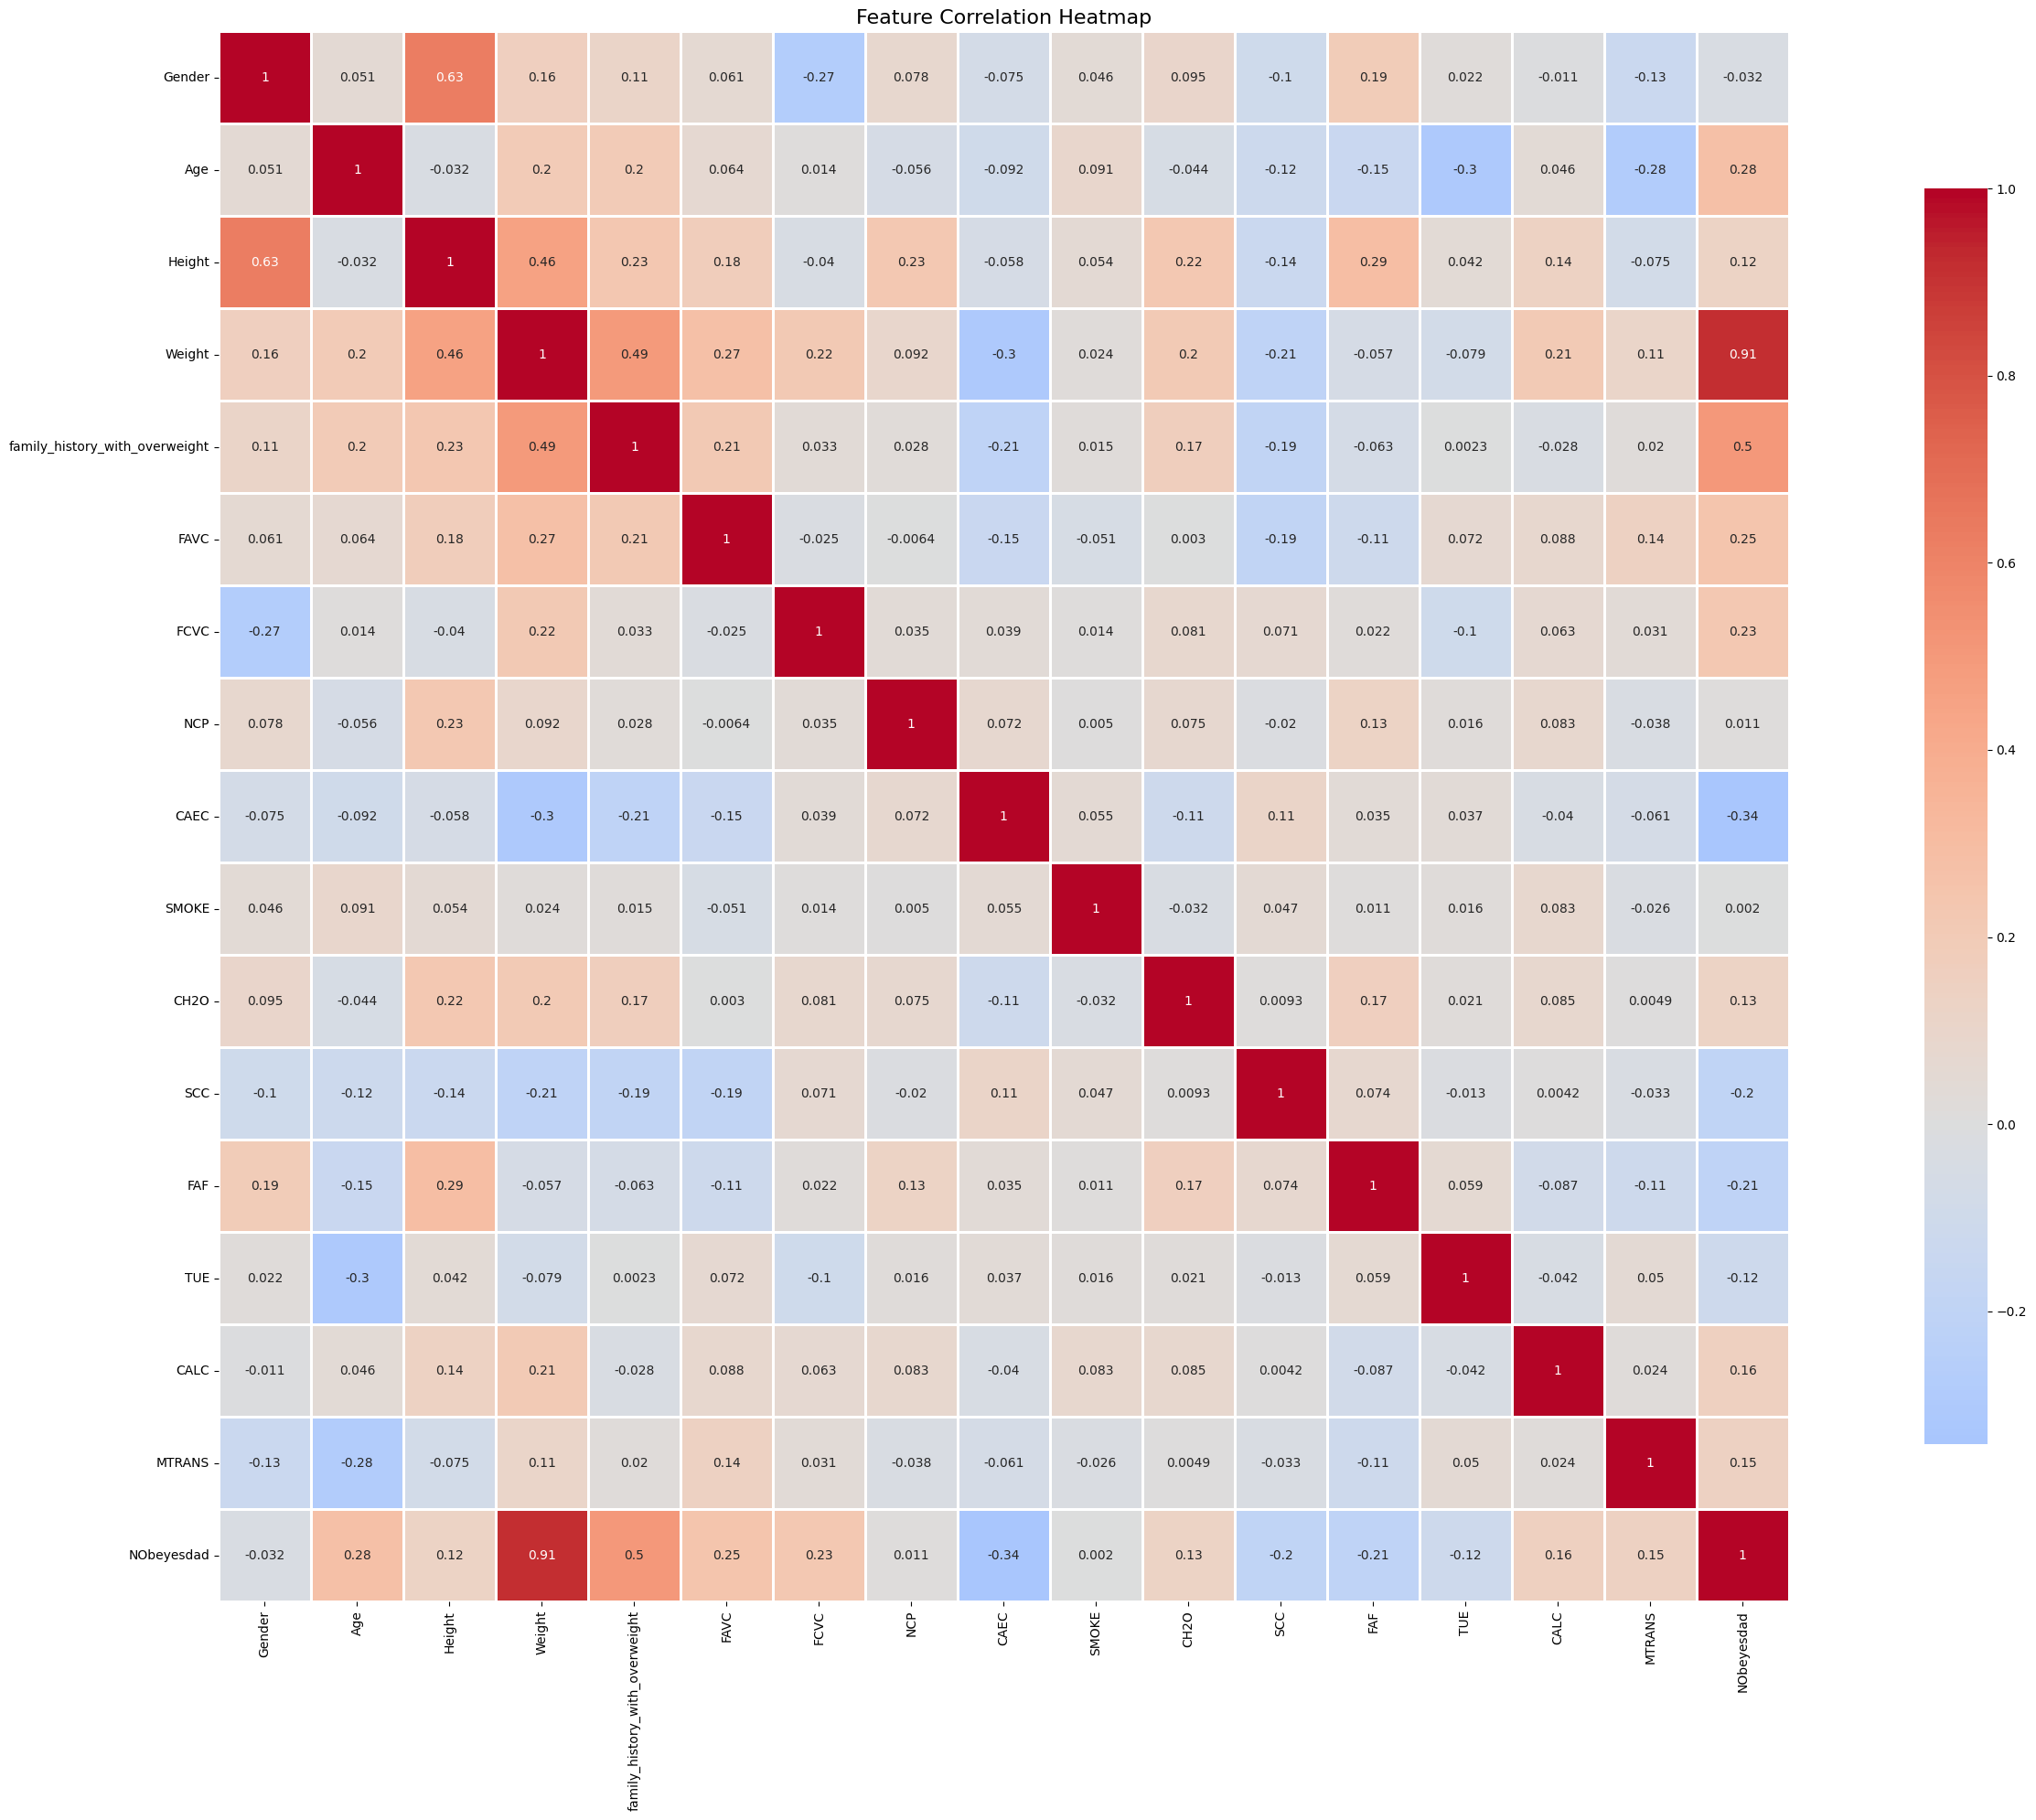

In [53]:
# Plot heatmap
plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()


In [54]:
# Top correlations with target
target_correlations = correlation_matrix[target[0]].sort_values(ascending=False)
print(target_correlations)

NObeyesdad                        1.000000
Weight                            0.912508
family_history_with_overweight    0.503374
Age                               0.279231
FAVC                              0.249927
FCVC                              0.228591
CALC                              0.155300
MTRANS                            0.149282
CH2O                              0.134170
Height                            0.124862
NCP                               0.011034
SMOKE                             0.001984
Gender                           -0.031920
TUE                              -0.115323
SCC                              -0.197819
FAF                              -0.206001
CAEC                             -0.342205
Name: NObeyesdad, dtype: float64


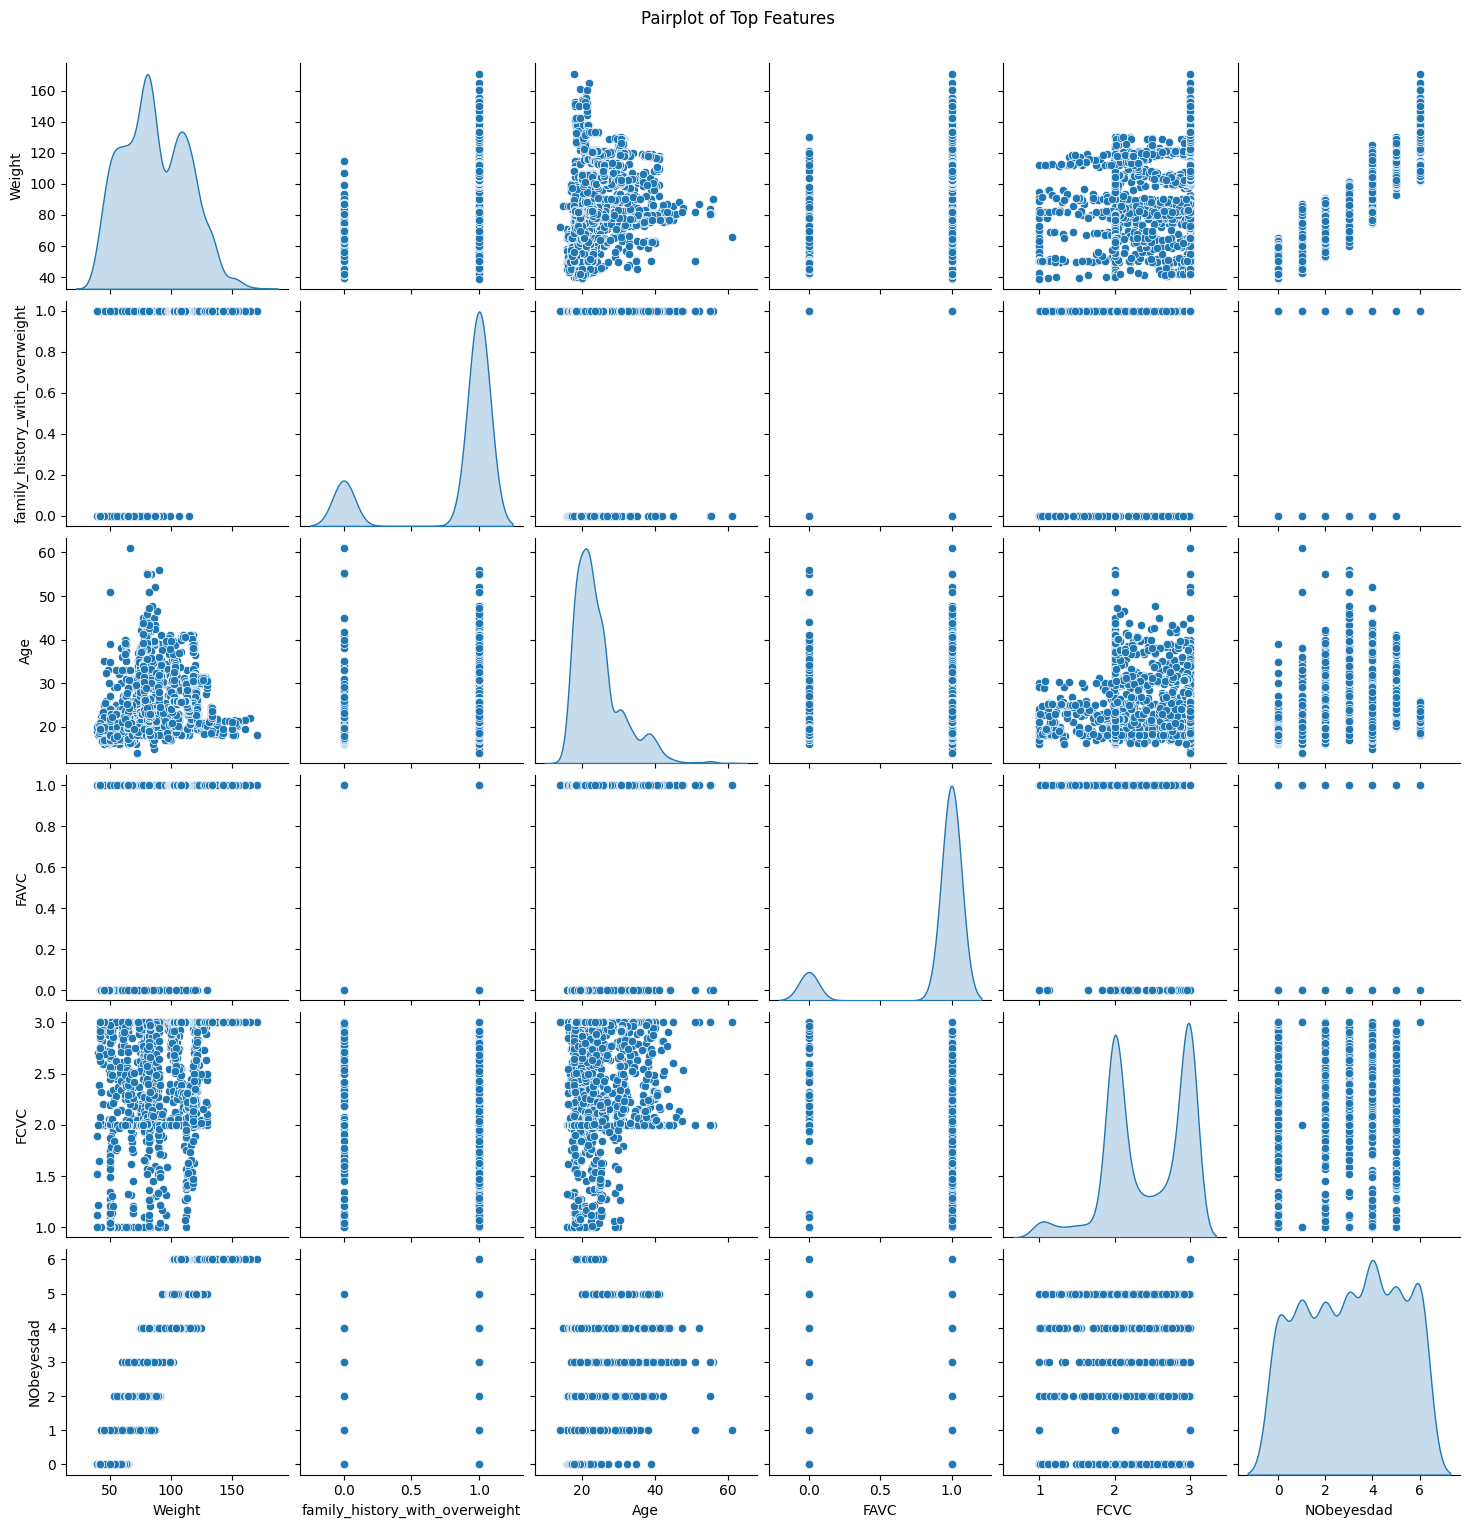

In [55]:
# Select top 4-5 features most correlated with target
top_features = target_correlations.index[1:6]  # Skip target itself

sns.pairplot(df[list(top_features) + [target[0]]], diag_kind='kde')
plt.suptitle('Pairplot of Top Features', y=1.02)
plt.show()

In [56]:
df.to_csv('Dataset/Portf_1_ObesityDataSet_synthetic.csv', index=False)

# AI Declaration

* I used Claude (Sonnet 4.6) to assist with suggestions on data preprocessing and encoding, chart interpretation, and polishing written explanations. All final code, interpretations, and conclusions are my own work, verified independently